In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import KFold, cross_val_score
import sklearn.metrics as metrics
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.append("..")   # Projektordner, damit Python den Ordner src findet
from src.features import FEATURES, feature_table

corp = feature_table("../data/corpus")   # eine Zeile pro Text: file, author, 12 Merkmale
colu = FEATURES
corp

# Decision Tree

In [6]:
X = corp[colu] # Features
y = corp["author"] # Target variable

In [7]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2) # 80% training and 20% test

# Create Decision Tree classifer object
clf = tree.DecisionTreeClassifier(random_state=42)

# Train Decision Tree Classifer
clf_fit = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf_fit.predict(X_test)

#X = corp.iloc[:,0:12]
#y = corp.iloc[:,12]

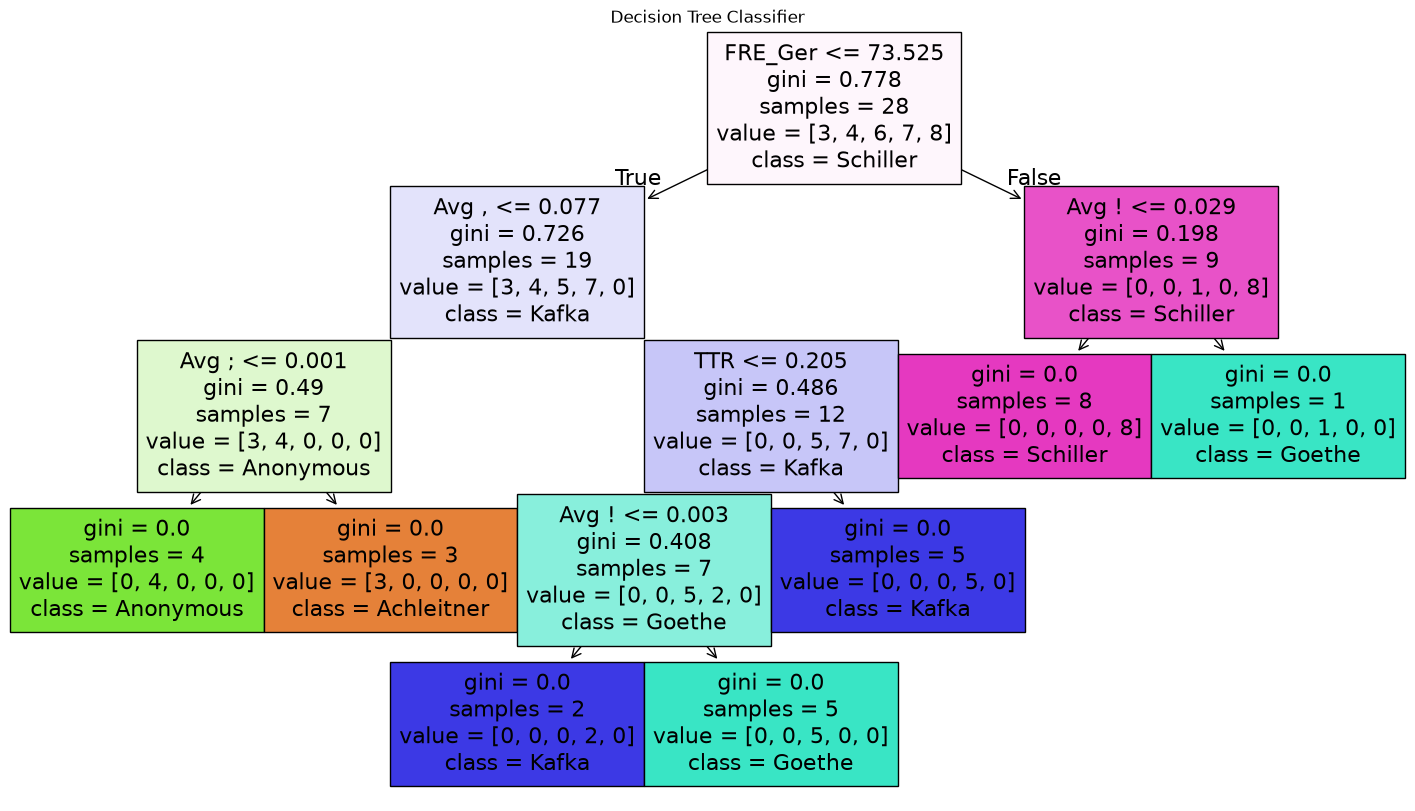

In [ ]:
plt.figure(figsize=(18, 10))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Achleitner', 'Anonymous', 'Goethe', 'Kafka', 'Schiller'])
plt.title("Decision Tree Classifier")
plt.show()

In [ ]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.75


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      0.50      0.67         2
      Goethe       0.50      1.00      0.67         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      0.50      0.67         2

    accuracy                           0.75         8
   macro avg       0.80      0.80      0.73         8
weighted avg       0.88      0.75      0.75         8



### 10 Fold Cross Valdidation

In [ ]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf_fit, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("\nAverage CV Score: ", scores.mean())
print("\nNumber of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.25       0.75       0.75       0.         0.75       0.25
 0.33333333 1.         0.66666667 0.33333333]

Average CV Score:  0.5083333333333333

Number of CV Scores used in Average:  10


In [ ]:
confusion_matrix(y_test, y_pred)

array([[2, 0, 0, 0, 0],
       [0, 1, 0, 1, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 1, 0, 1]])

In [ ]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
32,Schiller,Goethe
3,Achleitner,Achleitner


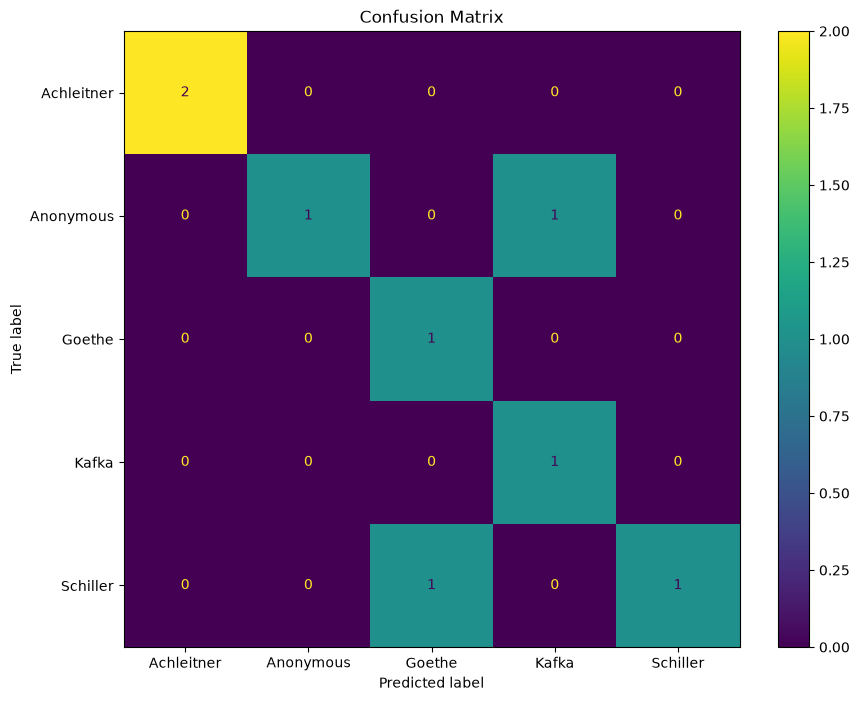

In [ ]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

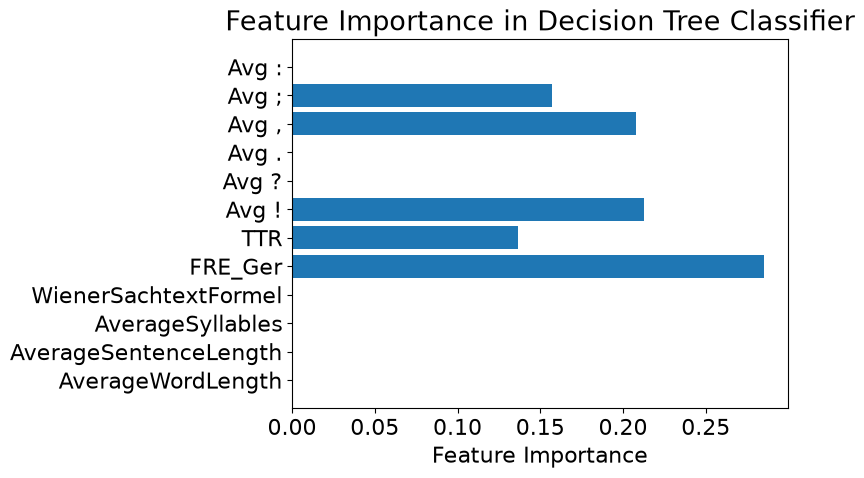

In [ ]:
feature_importances = clf_fit.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Decision Tree Classifier')
plt.show()

In [ ]:
features = pd.DataFrame(clf_fit.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.000000
AverageSentenceLength,0.000000
AverageSyllables,0.000000
WienerSachtextFormel,0.000000
FRE_Ger,0.285438
TTR,0.136612
Avg !,0.212750
Avg ?,0.000000
Avg .,0.000000
"Avg ,",0.207823
